# Regression Trees
### A walkthrough of `RegressionTree.py`

A **regression tree** predicts a *number* rather than a class. It uses the same recursive, axis-aligned partitioning as a classification tree, but each leaf predicts the **average** target value of its training samples, and splits are chosen to make the targets within each child as similar as possible. The result is a piecewise-constant approximation of the regression function.

This notebook builds that idea from first principles and runs the implementation in this folder (`RegressionTree.py`) at every step. By the end you should be able to:

1. state the regression problem in terms of squared-error risk and the conditional mean $E[y \mid x]$;
2. derive why a leaf should predict the mean, why "variance reduction" is the right split score, and the closed form $\Delta = w_L w_R(\bar y_L - \bar y_R)^2$;
3. explain how `DecisionTreeRegressor` searches, stops, stores and predicts, line by line;
4. work a complete example by hand and confirm every number against the code;
5. decompose a tree's test error into **bias², variance and noise**, and see how depth trades one for the other.

The tree-growing machinery (exhaustive threshold search, recursion, stopping rules, prediction by routing) is identical to the classification tree's. The [Decision Tree walkthrough](../DecisionTree/DecisionTree_Walkthrough.ipynb) derives it in detail. This notebook re-states it briefly and concentrates on what changes when the target is continuous.

**Pattern.** Each core topic follows **Concept → Math → Illustration → Your implementation → Check**. Cells titled *🔧 Fixed in the code* record bugs found while this notebook was being written and since corrected in `RegressionTree.py`: each gives the original behaviour, the fix, and a demonstration. Cells titled *⚠️ Note on the implementation* describe design choices that remain.

**Series:** [Decision Tree](../DecisionTree/DecisionTree_Walkthrough.ipynb) · **Regression Tree** · [Random Forest](../RandomForest/RandomForest_Walkthrough.ipynb) · [AdaBoost](../AdaBoost/AdaBoost_Walkthrough.ipynb) · [Gradient Boosting (regression)](../GradientBoostRegression/GradientBoostRegression_Walkthrough.ipynb) · [Gradient Boosting (classification)](../GradientBoostClassification/GradientBoostClassification_Walkthrough.ipynb) · [XGBoost](../XGBoost/XGBoost_Walkthrough.ipynb)

**Notation** (shared across the series). $X\in\mathbb{R}^{n\times m}$ holds $n$ samples of $m$ features. Features are indexed $j = 0,\dots,m-1$, matching the code's `X_0`, `X_1`, …. Here the targets are real numbers, $y_i \in \mathbb{R}$. $S$ is the set of samples at a node, with $|S|$ elements and mean target $\bar y_S = \frac{1}{|S|}\sum_{i\in S} y_i$. A split $(j,\tau)$ sends $x_j \le \tau$ to the left child $S_L$ and $x_j > \tau$ to the right child $S_R$; $w_L = |S_L|/|S|$ and $w_R = |S_R|/|S|$ are the child fractions. Leaf $\ell$ covers region $R_\ell$ and predicts the value $v_\ell$.

## 1. Setup

In [1]:
# Setup: imports, reproducibility, plot style, and the import path to the repo modules
import sys, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

NB_DIR = Path.cwd()                       # Jupyter starts the kernel in the notebook's own folder
assert (NB_DIR / "RegressionTree.py").exists(), "Open/run this notebook from inside the DecisionTreeRegression/ folder"
if str(NB_DIR) not in sys.path:
    sys.path.insert(0, str(NB_DIR))       # makes the repo modules in this folder importable

SEED = 0
rng = np.random.default_rng(SEED)         # the notebook's own generator for all synthetic data; it is independent
                                          # of NumPy's global random state and of the models' private generators
np.set_printoptions(precision=4, suppress=True)

# One plot style shared by every walkthrough notebook in this repo
plt.rcParams.update({
    "figure.figsize": (7, 4.5), "figure.dpi": 100,
    "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.labelsize": 11, "legend.fontsize": 9, "legend.frameon": False,
})
CLASS_COLORS  = ["#1f77b4", "#d62728", "#2ca02c", "#9467bd"]   # class 0, 1, 2, 3 (points)
REGION_COLORS = ["#c6dbef", "#fcbba1", "#c7e9c0", "#dadaeb"]   # class 0, 1, 2, 3 (decision regions)

In [2]:
# Teaching helpers — Illustration only, not the repo implementation.
# Synthetic-data generators, a train/test split, a decision-region plotter, and read-only
# inspectors that walk the Node objects built by the repo code (they never modify a tree).

def make_xor(n, noise=0.0, rng=rng):
    """Points uniform on [-1, 1]^2; class 1 when x0*x1 < 0 (2nd and 4th quadrants). `noise` = label-flip rate."""
    X = rng.uniform(-1, 1, size=(n, 2))
    y = (X[:, 0] * X[:, 1] < 0).astype(float)
    flip = rng.random(n) < noise
    y[flip] = 1 - y[flip]
    return X, y

def make_moons(n, noise=0.2, rng=rng):
    """Two interleaving half-circles with Gaussian jitter (the classic 'moons' toy problem)."""
    n0 = n // 2; n1 = n - n0
    t0, t1 = rng.uniform(0, np.pi, n0), rng.uniform(0, np.pi, n1)
    X = np.r_[np.c_[np.cos(t0), np.sin(t0)], np.c_[1 - np.cos(t1), 0.5 - np.sin(t1)]]
    X = X + noise * rng.normal(size=(n, 2))
    return X, np.r_[np.zeros(n0), np.ones(n1)]

def make_blobs(n, centers, std=1.0, rng=rng):
    """Gaussian clusters; the label is the index of the cluster a point came from."""
    centers = np.asarray(centers, dtype=float)
    y = rng.integers(0, len(centers), size=n)
    X = centers[y] + std * rng.normal(size=(n, centers.shape[1]))
    return X, y.astype(float)

def noisy_sine(n, noise=0.3, rng=rng):
    """1-D regression toy problem: y = sin(x) + Gaussian noise, x uniform on [0, 2*pi]."""
    x = np.sort(rng.uniform(0, 2 * np.pi, n))
    return x.reshape(-1, 1), np.sin(x) + noise * rng.normal(size=n)

def train_test_split_np(X, y, test_frac=0.3, rng=rng):
    """Random train/test split with NumPy only."""
    idx = rng.permutation(len(X))
    n_test = int(round(test_frac * len(X)))
    te, tr = idx[:n_test], idx[n_test:]
    return X[tr], X[te], y[tr], y[te]

def iter_nodes(node):
    """Yield every node of a tree in pre-order (works with every Node class in this repo)."""
    if node is None:
        return
    yield node
    if node.value is None:                       # decision node: recurse into both children
        yield from iter_nodes(node.left)
        yield from iter_nodes(node.right)

def tree_depth(node):
    """Number of edges on the longest root-to-leaf path (a single leaf has depth 0)."""
    return 0 if node.value is not None else 1 + max(tree_depth(node.left), tree_depth(node.right))

def count_leaves(node):
    return sum(1 for nd in iter_nodes(node) if nd.value is not None)

def plot_decision_regions(predict_fn, X, y, ax=None, title="", grid_n=120, pad=0.4, legend=True):
    """Colour a grid by predict_fn's class label, then overlay the data points coloured by true class."""
    ax = ax or plt.gca()
    g0 = np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, grid_n)
    g1 = np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, grid_n)
    G0, G1 = np.meshgrid(g0, g1)
    Z = np.asarray(predict_fn(np.c_[G0.ravel(), G1.ravel()]), dtype=float).reshape(G0.shape)
    K = int(max(Z.max(), y.max())) + 1
    ax.contourf(G0, G1, Z, levels=np.arange(K + 1) - 0.5, cmap=ListedColormap(REGION_COLORS[:K]))
    for k in range(K):
        m = y == k
        ax.scatter(X[m, 0], X[m, 1], s=16, c=CLASS_COLORS[k], edgecolor="white", linewidth=0.4, label=f"class {k}")
    ax.set_title(title); ax.set_xlabel("$x_0$"); ax.set_ylabel("$x_1$")
    if legend:
        ax.legend(loc="upper right", frameon=True, framealpha=0.8)
    return ax

In [3]:
# The implementation under study: imported from RegressionTree.py, never copied into this notebook
import RegressionTree as rt_mod
from RegressionTree import DecisionTreeRegressor, Node

print("module:", Path(rt_mod.__file__).name)
print("DecisionTreeRegressor methods:", [k for k in vars(DecisionTreeRegressor) if not k.startswith("__")])

module: RegressionTree.py
DecisionTreeRegressor methods: ['build_tree', 'get_best_split', 'split', 'variance_reduction', 'calculate_leaf_value', 'print_tree', 'fit', 'make_prediction', 'predict']


## 2. The problem: regression under squared error

We observe pairs $(x_i, y_i)$ with $x_i \in \mathbb{R}^m$ and a **real-valued** target $y_i$, drawn independently from an unknown distribution. We want a function $\hat f$ whose predictions are close to $y$ on new data. Closeness is measured by the *squared-error risk*

$$
R(\hat f) = E\big[(y - \hat f(x))^2\big].
$$

**The best possible predictor is the conditional mean.** Fix an input $x$ and consider predicting a constant $c$ for it. Write $\mu(x) = E[y\mid x]$ and expand around it:

$$
E\big[(y-c)^2 \mid x\big] = E\big[(y-\mu(x))^2 \mid x\big] + 2\,(\mu(x)-c)\,E\big[y-\mu(x)\mid x\big] + (\mu(x)-c)^2 = \mathrm{Var}(y\mid x) + (\mu(x)-c)^2 .
$$

The middle term vanishes because $E[y - \mu(x)\mid x] = 0$ by definition of $\mu$. The first term does not depend on $c$, so the risk is minimised by $c = \mu(x)$. The minimum achievable risk is the noise variance $E[\mathrm{Var}(y\mid x)]$, called the *irreducible error*. A regression method is therefore an estimator of $\mu(x) = E[y\mid x]$.

**What makes it hard:** $\mu$ can be non-linear and can involve interactions between features; the observations are noisy; and with finite data a flexible model can chase the noise instead of $\mu$.

The running example is a noisy sine wave, $y = \sin(x) + \varepsilon$ with $\varepsilon \sim \mathcal{N}(0, 0.3^2)$, so $\mu(x) = \sin x$ and the irreducible error is $0.3^2 = 0.09$.

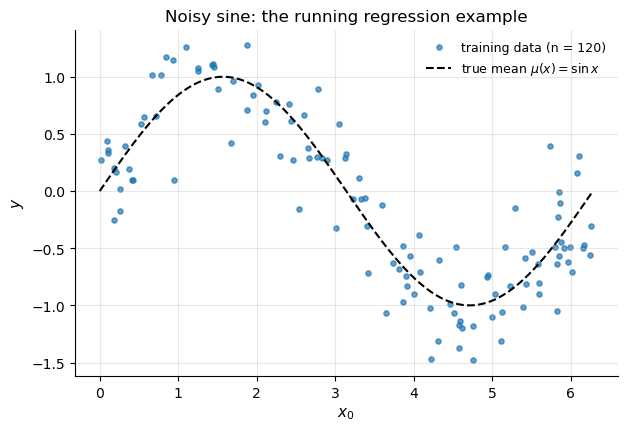

In [4]:
SIGMA = 0.3
X_sin, y_sin = noisy_sine(120, noise=SIGMA)
X_sin_test, y_sin_test = noisy_sine(2000, noise=SIGMA)
x_grid = np.linspace(0, 2 * np.pi, 400).reshape(-1, 1)

fig, ax = plt.subplots()
ax.scatter(X_sin, y_sin, s=14, color=CLASS_COLORS[0], alpha=0.7, label="training data (n = 120)")
ax.plot(x_grid, np.sin(x_grid), "k--", lw=1.5, label="true mean $\\mu(x) = \\sin x$")
ax.set(title="Noisy sine: the running regression example", xlabel="$x_0$", ylabel="$y$")
ax.legend(); plt.show()

The dashed curve is the target we would like to recover. The scatter around it is the noise $\varepsilon$, which no model can predict. A good regressor follows the curve, not the scatter.

## 3. Why a regression tree fits this problem

A regression tree approximates $\mu(x)$ by a **step function**:

$$
\hat f(x) = \sum_{\ell=1}^{L} v_\ell\, \mathbb{1}[x \in R_\ell], \qquad v_\ell \in \mathbb{R}, \tag{0}
$$

where the boxes $R_\ell$ come from recursive axis-aligned splits. Each leaf estimates $\mu$ by averaging the training targets that fall in its box, a *local average*. With enough leaves, a step function can approximate any reasonable $\mu$, and the tree chooses *where* to place the steps from the data: many steps where $\mu$ changes quickly, few where it is flat.

It inherits the classification tree's strengths: no feature scaling (only the order of feature values matters), automatic handling of interactions, and interpretability. It also inherits the weaknesses: greedy splits, axis-aligned boundaries, and high variance. Two weaknesses are specific to regression:
- **Non-smoothness.** The prediction jumps at every threshold, even when $\mu$ is smooth.
- **No extrapolation.** Outside the training range, the prediction is the constant value of the outermost leaf (Section 7.4).

Regression trees also matter because they are the **weak learner inside gradient boosting**. [Gradient boosting](../GradientBoostRegression/GradientBoostRegression_Walkthrough.ipynb) fits a sequence of small regression trees, each to the errors of the ones before it, and even the boosting *classifiers* in this repo use regression trees internally.

## 4. Core concepts, theory and math

### 4.1 The leaf value: the mean minimises squared error

**Concept.** Once the tree has decided which training samples share a leaf, it must choose one number to predict for all of them. The natural criterion is the leaf's training squared error.

**Math.** For a leaf with sample set $S$, choose $c$ to minimise $\mathrm{SSE}(c) = \sum_{i\in S}(y_i - c)^2$. It is a convex quadratic in $c$, and

$$
\frac{d}{dc}\mathrm{SSE}(c) = -2\sum_{i \in S}(y_i - c) = -2\Big(\sum_{i\in S} y_i - |S|\,c\Big) = 0 \quad\Longrightarrow\quad c^* = \frac{1}{|S|}\sum_{i\in S} y_i = \bar y_S . \tag{1}
$$

The second derivative is $2|S| > 0$, so this is the minimum. At the optimum, the SSE equals $|S|$ times the (population) variance of the targets:

$$
\mathrm{SSE}(\bar y_S) = \sum_{i\in S}(y_i - \bar y_S)^2 = |S|\cdot \mathrm{Var}(S), \qquad \mathrm{Var}(S) = \frac{1}{|S|}\sum_{i\in S}(y_i-\bar y_S)^2. \tag{2}
$$

So the variance of a node is its average squared error *when it predicts its own mean*. Variance plays the role for regression that impurity plays for classification.

**Illustration.** The SSE of a constant prediction, as a function of the constant.

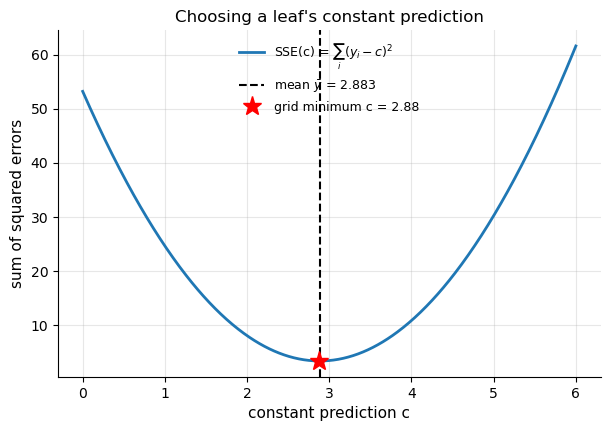

In [5]:
# Illustration only — SSE(c) for one leaf's targets; the minimum sits at the mean (Eq. 1)
y_leaf = np.array([2.1, 2.9, 3.4, 1.8, 4.0, 3.1])
cs = np.linspace(0, 6, 601)
sse = ((y_leaf[None, :] - cs[:, None]) ** 2).sum(axis=1)
c_best = cs[np.argmin(sse)]

fig, ax = plt.subplots()
ax.plot(cs, sse, lw=2, label="SSE(c) = $\\sum_i (y_i - c)^2$")
ax.axvline(y_leaf.mean(), color="k", ls="--", label=f"mean $\\bar y$ = {y_leaf.mean():.3f}")
ax.plot(c_best, sse.min(), "r*", ms=14, label=f"grid minimum c = {c_best:.2f}")
ax.set(title="Choosing a leaf's constant prediction", xlabel="constant prediction c", ylabel="sum of squared errors")
ax.legend(); plt.show()

The SSE is a parabola in $c$, and its lowest point is at the sample mean. Any other constant pays an extra $|S|\,(c - \bar y_S)^2$, by the same expansion as in Section 2.

**Your implementation.** `calculate_leaf_value(Y)` returns `np.mean(Y)`.

In [6]:
reg = DecisionTreeRegressor()                       # fresh instance, used only for its helper methods
print("calculate_leaf_value(y_leaf) =", reg.calculate_leaf_value(y_leaf))

calculate_leaf_value(y_leaf) = 2.8833333333333333


In [7]:
# Check — Eq. (1): the repo's leaf value is the SSE-minimising constant, and Eq. (2) links SSE to variance
v = reg.calculate_leaf_value(y_leaf)
assert np.isclose(v, y_leaf.mean()) and abs(v - c_best) <= 0.01            # grid resolution is 0.01
assert np.isclose(((y_leaf - v) ** 2).sum(), len(y_leaf) * np.var(y_leaf))
print(f"✓ leaf value {v:.4f} = mean = SSE minimiser; SSE at the mean = |S|·Var(S) = {len(y_leaf) * np.var(y_leaf):.4f}")

✓ leaf value 2.8833 = mean = SSE minimiser; SSE at the mean = |S|·Var(S) = 3.3483


The leaf value is exactly the mean (Eq. 1), the constant that minimises squared error. Its SSE equals $|S|\,\mathrm{Var}(S)$ (Eq. 2). Note that `np.var` uses the *population* variance (dividing by $|S|$, not $|S|-1$), which is the version that makes Eq. (2) hold exactly.

### 4.2 Scoring a split: variance reduction

**Concept.** A split replaces one mean, $\bar y_S$, by two, $\bar y_{S_L}$ and $\bar y_{S_R}$. A good split groups samples with similar targets, so each child's mean fits its members better than the parent's mean did. The implementation scores this improvement as the **variance reduction**:

$$
\Delta(S;j,\tau) = \mathrm{Var}(S) - \big(w_L\,\mathrm{Var}(S_L) + w_R\,\mathrm{Var}(S_R)\big), \qquad w_L = \tfrac{|S_L|}{|S|},\; w_R = \tfrac{|S_R|}{|S|}. \tag{3}
$$

This is Eq. (3) of the [classification notebook](../DecisionTree/DecisionTree_Walkthrough.ipynb) with impurity replaced by variance.

**Math, part 1: it is the drop in training SSE.** Multiply Eq. (3) by $|S|$ and use Eq. (2) for each node:

$$
|S|\,\Delta = |S|\mathrm{Var}(S) - |S_L|\mathrm{Var}(S_L) - |S_R|\mathrm{Var}(S_R) = \mathrm{SSE}(S) - \mathrm{SSE}(S_L) - \mathrm{SSE}(S_R). \tag{4}
$$

So maximising $\Delta$ is the same as choosing the split that most reduces the training squared error of the tree, which is exactly what the squared-error objective of Section 2 asks for. (The common factor $1/|S|$ does not change which split wins within a node.)

**Math, part 2: a closed form.** Decompose each sample's deviation from the parent mean as $y_i - \bar y_S = (y_i - \bar y_{c}) + (\bar y_c - \bar y_S)$, where $c \in \{L, R\}$ is the child containing $i$. Squaring and summing within child $c$, the cross term $2(\bar y_c - \bar y_S)\sum_{i\in S_c}(y_i - \bar y_c)$ vanishes, because deviations from a mean sum to zero. This leaves

$$
\mathrm{SSE}(S) = \underbrace{\mathrm{SSE}(S_L) + \mathrm{SSE}(S_R)}_{\text{within children}} + \underbrace{|S_L|(\bar y_L - \bar y_S)^2 + |S_R|(\bar y_R - \bar y_S)^2}_{\text{between children}} .
$$

So $|S|\Delta$ equals the *between-children* sum of squares. Substitute $\bar y_S = w_L\bar y_L + w_R \bar y_R$, which gives $\bar y_L - \bar y_S = w_R(\bar y_L - \bar y_R)$ and $\bar y_R - \bar y_S = -w_L(\bar y_L - \bar y_R)$. Then

$$
|S|\Delta = |S| w_L\, w_R^2(\bar y_L-\bar y_R)^2 + |S| w_R\, w_L^2(\bar y_L-\bar y_R)^2 = |S|\, w_L w_R (w_L + w_R)(\bar y_L - \bar y_R)^2,
$$

and since $w_L + w_R = 1$,

$$
\boxed{\;\Delta(S;j,\tau) = w_L\, w_R\, (\bar y_L - \bar y_R)^2 \;\ge 0.\;} \tag{5}
$$

Eq. (5) makes the trade-off visible. A split is valuable when the two child means are **far apart**, and when the children are **balanced** ($w_L w_R$ is largest at $w_L = w_R = \tfrac12$). Peeling off a single extreme point gives a large mean difference but a tiny $w_L w_R$. The gain is never negative, and it is zero only when the two child means are equal.

**Illustration.** Eqs. (3), (4) and (5) computed three different ways for one split.

In [8]:
# Illustration only — the three equivalent forms of the variance reduction for one split
y_par = np.array([1.0, 1.4, 0.6, 3.6, 4.4, 4.0, 2.2, 2.6])
yL, yR = y_par[:3], y_par[3:]
wL, wR = len(yL) / len(y_par), len(yR) / len(y_par)
d_var  = np.var(y_par) - (wL * np.var(yL) + wR * np.var(yR))                               # Eq. (3)
sse    = lambda a: ((a - a.mean()) ** 2).sum()
d_sse  = (sse(y_par) - sse(yL) - sse(yR)) / len(y_par)                                      # Eq. (4)
d_mean = wL * wR * (yL.mean() - yR.mean()) ** 2                                              # Eq. (5)
print(f"Eq.(3) variance form   : {d_var:.6f}")
print(f"Eq.(4) SSE form / |S|  : {d_sse:.6f}")
print(f"Eq.(5) w_L w_R (Δmean)²: {d_mean:.6f}   (w_L = {wL:.3f}, means {yL.mean():.3f} vs {yR.mean():.3f})")

Eq.(3) variance form   : 1.305375
Eq.(4) SSE form / |S|  : 1.305375
Eq.(5) w_L w_R (Δmean)²: 1.305375   (w_L = 0.375, means 1.000 vs 3.360)


**Your implementation.** `variance_reduction(parent, l_child, r_child)` takes the three target arrays.

In [9]:
d_repo = reg.variance_reduction(y_par, yL, yR)
print(f"variance_reduction(...) = {d_repo:.6f}")

variance_reduction(...) = 1.305375


In [10]:
# Check — the repo matches all three forms, and is never negative over many random splits
assert np.isclose(d_repo, d_var) and np.isclose(d_repo, d_sse) and np.isclose(d_repo, d_mean)
worst = np.inf
for _ in range(1000):
    y_ = rng.normal(size=rng.integers(2, 30)); s = rng.integers(1, len(y_))
    dr = reg.variance_reduction(y_, y_[:s], y_[s:])
    assert np.isclose(dr, (s / len(y_)) * (1 - s / len(y_)) * (y_[:s].mean() - y_[s:].mean()) ** 2)
    worst = min(worst, dr)
print(f"✓ variance_reduction = Eq.(3) = Eq.(4) = Eq.(5); over 1,000 random splits it matched Eq.(5) "
      f"and its minimum was {worst:.2e} (≥ 0 up to rounding)")

✓ variance_reduction = Eq.(3) = Eq.(4) = Eq.(5); over 1,000 random splits it matched Eq.(5) and its minimum was 8.80e-08 (≥ 0 up to rounding)


`variance_reduction` computes Eq. (3) directly with `np.var`. The check confirms it equals the SSE drop of Eq. (4) and the closed form of Eq. (5), and is therefore never negative (up to floating-point rounding).

### 4.3 Searching for the best split

**Concept.** Exactly as for classification, the repo tries every feature $j$ and every distinct observed value $\tau$ of that feature as a threshold. It keeps the candidate with the largest $\Delta$, the first one met in case of ties (`curr_var_red > max_var_red`, strict), and skips candidates that leave a child empty:

$$
(j^*, \tau^*) = \arg\max_{j,\ \tau \in \{\text{distinct values of } x_j \text{ in } S\}} \Delta(S; j, \tau). \tag{6}
$$

**Illustration.** The variance reduction of every threshold on the noisy-sine training data. Eq. (5) explains the shape: the best single split separates the high part of the sine from the low part.

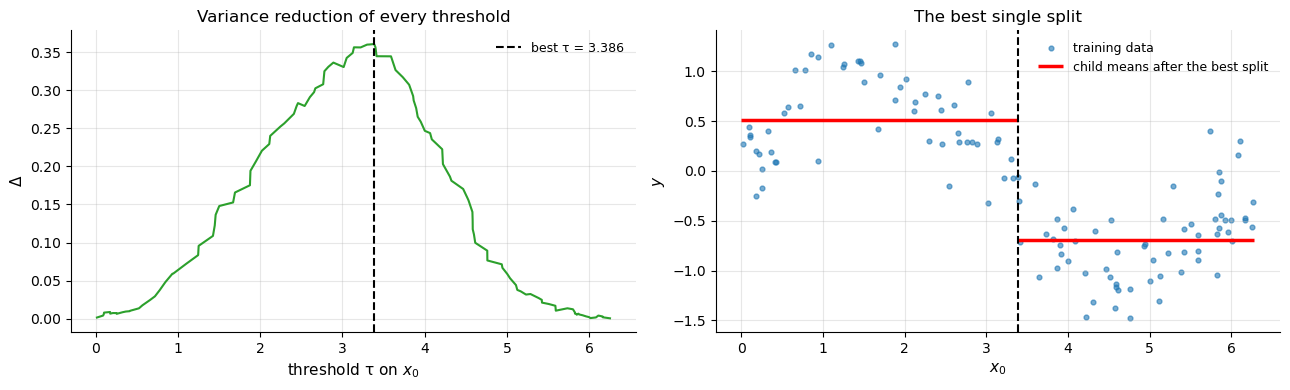

In [11]:
# Illustration only — Eq. (5) evaluated at every candidate threshold of the 1-D sine data
def scan_var_red(x, y):
    taus, gains = [], []
    for tau in np.unique(x)[:-1]:                          # the largest value would leave the right child empty
        left = x <= tau
        gains.append(left.mean() * (1 - left.mean()) * (y[left].mean() - y[~left].mean()) ** 2)
        taus.append(tau)
    return np.array(taus), np.array(gains)

taus, gains = scan_var_red(X_sin.ravel(), y_sin)
tau_best = taus[np.argmax(gains)]                          # argmax returns the first maximum, like the repo

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(taus, gains, color=CLASS_COLORS[2])
axes[0].axvline(tau_best, color="k", ls="--", label=f"best τ = {tau_best:.3f}")
axes[0].set(title="Variance reduction of every threshold", xlabel="threshold τ on $x_0$", ylabel="Δ"); axes[0].legend()
left = X_sin.ravel() <= tau_best
axes[1].scatter(X_sin, y_sin, s=12, alpha=0.6, color=CLASS_COLORS[0], label="training data")
axes[1].hlines([y_sin[left].mean(), y_sin[~left].mean()], [0, tau_best], [tau_best, 2 * np.pi], colors="r", lw=2.5,
               label="child means after the best split")
axes[1].axvline(tau_best, color="k", ls="--")
axes[1].set(title="The best single split", xlabel="$x_0$", ylabel="$y$"); axes[1].legend()
plt.tight_layout(); plt.show()

The gain curve peaks near $x = \pi$, where $\sin x$ changes sign. Splitting there separates the positive half of the wave from the negative half: the two child means are far apart, and the children are about equally large, which is exactly the combination Eq. (5) rewards. A threshold near the ends of the range has a tiny $w_L w_R$ and gains almost nothing.

**Your implementation.** `get_best_split(dataset, num_samples, num_features)` takes the data with targets appended as the last column and returns the winning `feature_index`, `threshold` and `var_red`, plus both child data sets.

In [12]:
ds_sin = np.c_[X_sin, y_sin]
best = reg.get_best_split(ds_sin, *X_sin.shape)
print({k: (f"array of shape {v.shape}" if isinstance(v, np.ndarray) else v) for k, v in best.items()})

{'feature_index': 0, 'threshold': np.float64(3.386224751505259), 'dataset_left': 'array of shape (57, 2)', 'dataset_right': 'array of shape (63, 2)', 'var_red': np.float64(0.36105858452535655)}


In [13]:
# Check — the repo's search returns the arg-max of the independent scan, Eq. (6)
assert best["feature_index"] == 0 and best["threshold"] == tau_best
assert np.isclose(best["var_red"], gains.max())
print(f"✓ get_best_split chose x_0 <= {tau_best:.4f} with Δ = {gains.max():.4f}, the maximum over all {len(taus)} candidates")

✓ get_best_split chose x_0 <= 3.3862 with Δ = 0.3611, the maximum over all 119 candidates


The repo's exhaustive search agrees with the independent scan on the threshold and the gain.

### 4.4 Recursion and stopping

The recursion is the same as in the classification tree. `build_tree` splits a node if it has at least `min_samples_split` samples, the depth test passes, and its targets are not all equal (`np.ptp(Y) > 0`), and then only if the best variance reduction is positive. Otherwise it makes a leaf whose value is the mean (Eq. 1). The equal-targets test is a cheap shortcut: by Eq. (5), such a node has $\Delta = 0$ for every split anyway, and skipping the search also avoids treating floating-point round-off in `np.var` as a tiny positive gain.

> 🔧 **Fixed in the code — `max_depth` now means what it says.**
> *Originally:* as in `DecisionTree.py`, the depth test was `curr_depth<=self.max_depth`, so leaves reached depth `max_depth + 1`; even `max_depth=0` split once. `Main.py` compares this tree with scikit-learn's at `max_depth=3`, so the two trees there had different depths (4 versus 3), which skewed the RMSE comparison it prints.
> *Now:* `curr_depth < self.max_depth` (RegressionTree.py, lines 47–48), and `max_depth=None` means unlimited. To reproduce a tree from before the fix, add 1 to `max_depth`.

In [14]:
print("max_depth | actual depth | leaves")
for md in [0, 1, 2, 3, 4, 5]:
    t = DecisionTreeRegressor(min_samples_split=2, max_depth=md)
    t.fit(X_sin, y_sin)                                     # 1-D targets are accepted (a column vector also works)
    print(f"{md:>9} | {tree_depth(t.root):>12} | {count_leaves(t.root):>6}")
    assert tree_depth(t.root) == md
print("✓ every tree is exactly max_depth deep")

max_depth | actual depth | leaves
        0 |            0 |      1
        1 |            1 |      2
        2 |            2 |      4
        3 |            3 |      8
        4 |            4 |     15


        5 |            5 |     28
✓ every tree is exactly max_depth deep


Each tree is now exactly `max_depth` deep, and `max_depth=0` is a single leaf that predicts the overall mean.

> 🔧 **Fixed in the code — nodes whose rows are identical used to crash `fit`.**
> *Originally:* if all samples in a node had the same feature vector, no threshold could yield two non-empty children, so `get_best_split` returned `{}` and `build_tree` failed on `best_split["var_red"]` with a `KeyError`. This even happened when all the targets were equal. It is more likely in regression data with discrete or repeated feature values. (The airfoil data used by `Main.py`, for example, has only a handful of distinct values in several columns.)
> *Now:* the test is `best_split.get("var_red", -inf) > 0` (line 54), so such a node becomes a leaf. The same edit removed an unused `best_split = {}` that `build_tree` used to initialise before the `if`.

In [15]:
for X_dup, y_dup, desc in [(np.array([[1.0], [1.0], [1.0]]), np.array([0.5, 1.5, 2.5]), "identical x, different y"),
                           (np.array([[3.0], [3.0]]), np.array([2.0, 2.0]), "identical x, identical y")]:
    t = DecisionTreeRegressor(min_samples_split=2, max_depth=3)
    t.fit(X_dup, y_dup)
    print(f"{desc:<26}: fit succeeded -> a single leaf predicting {t.root.value:.3f} (the mean)")
    assert t.root.value is not None and np.isclose(t.root.value, y_dup.mean())

identical x, different y  : fit succeeded -> a single leaf predicting 1.500 (the mean)
identical x, identical y  : fit succeeded -> a single leaf predicting 2.000 (the mean)


Both former crash cases now produce a single leaf predicting the mean of the targets. That is the right answer, because identical inputs cannot be told apart.

### 4.5 Prediction: a step function

**Concept and math.** As in classification, a new point is routed from the root to a leaf ($x_j \le \tau$ goes left) and receives that leaf's mean, so the fitted function is the step function of Eq. (0). Prediction costs $O(\text{depth})$ comparisons per point.

**Illustration and check.** A hand-written router over your `Node` objects should agree with `predict` everywhere.

In [16]:
# Illustration only — route points through the repo's Node objects by hand
def route(x, node):
    while node.value is None:
        node = node.left if x[node.feature_index] <= node.threshold else node.right
    return node.value

t3 = DecisionTreeRegressor(min_samples_split=2, max_depth=3); t3.fit(X_sin, y_sin.reshape(-1, 1))
pred_repo = np.array(t3.predict(x_grid))
pred_hand = np.array([route(x, t3.root) for x in x_grid])
assert np.array_equal(pred_repo, pred_hand)
print(f"✓ predict() equals hand routing on all {len(x_grid)} grid points; "
      f"the tree has {count_leaves(t3.root)} leaves, so predict() takes {len(np.unique(pred_repo))} distinct values")

✓ predict() equals hand routing on all 400 grid points; the tree has 8 leaves, so predict() takes 8 distinct values


A tree with $L$ leaves can output at most $L$ different numbers. Here it outputs exactly one value per leaf, so the prediction is a staircase with $L$ steps.

## 5. Implementation walkthrough, in the order the code runs

```
fit(X, Y) ── concatenate ──> build_tree(dataset, curr_depth=0)
                               ├── get_best_split(dataset, n, m)
                               │      └── for each feature j, each unique value τ:
                               │              split(dataset, j, τ)            → S_L, S_R
                               │              variance_reduction(y, yL, yR)   → Δ (Eq. 3)
                               ├── if Δ* > 0: Node(j, τ, build_tree(S_L), build_tree(S_R), Δ*)
                               └── else:      Node(value = calculate_leaf_value(Y))   (Eq. 1)
predict(X) ── for each row ──> make_prediction(x, root)
```

**`Node` (lines 14–26).** A decision node stores `feature_index`, `threshold`, `left`, `right` and `var_red` (the winning $\Delta$, used only by `print_tree`). A leaf stores `value`, the mean target $v_\ell$. Code distinguishes the two by testing whether `value` is `None`.

**`DecisionTreeRegressor.__init__(min_samples_split=2, max_depth=2)` (lines 29–37).** Stores the two stopping parameters. Note the spelling `min_samples_split` (as in scikit-learn); the classifier in `DecisionTree.py` calls the same parameter `min_samp_split`.

**`fit(X, Y)` (lines 136–149).** Converts `X` and `Y` to float arrays and reshapes a 1-D `Y` into a column. (The original required shape `(n, 1)` and crashed otherwise.) It raises `ValueError` for mismatched or empty input. Then `dataset = np.concatenate((X, Y), axis=1)` appends the targets as the last column, and `self.root = self.build_tree(dataset)`.

**`build_tree(dataset, curr_depth=0)` (lines 39–66).** Splits `dataset` into features and targets and applies the stopping rules (`num_samples>=self.min_samples_split and depth_ok and np.ptp(Y) > 0`). It calls `get_best_split`, checks `best_split.get("var_red", -inf)>0`, and recurses or returns a mean-valued leaf.

**`get_best_split(dataset, num_samples, num_features)` (lines 68–97).** Eq. (6). It loops over features, then over `np.unique(feature_values)`; skips empty children; scores each candidate with `variance_reduction`; and keeps the strictly-best one.

**`split(dataset, feature_index, threshold)` (lines 99–104).** The same Python list comprehensions as the classifier (`row[feature_index]<=threshold` goes left). This is $O(|S|)$ Python work per candidate, so the full search at a node is $O(m\,|S|^2)$; the [classification notebook](../DecisionTree/DecisionTree_Walkthrough.ipynb#9.-Complexity-and-limitations) measures this quadratic cost.

**`variance_reduction(parent, l_child, r_child)` (lines 106–112).** Eq. (3), using `np.var` (population variance) and child weights `len(child)/len(parent)`.

**`calculate_leaf_value(Y)` (lines 114–118).** Eq. (1), `np.mean(Y)`.

**`print_tree(tree=None, indent=" ")` (lines 120–134).** Prints `X_j <= τ ? Δ` for decision nodes and the mean for leaves. The default indent is a single space, doubled at each level.

**`make_prediction(x, tree)` and `predict(X)` (lines 151–164).** Recursive routing; a leaf is detected with `tree.value is not None`. (Their docstrings used to be swapped, with the per-point method saying "predict new dataset" and the whole-matrix method "predict a single data point". They have been corrected.)

**The other files.** `Main.py` loads `airfoil_noise_data.csv` (1,503 rows: five numeric features `x0`–`x4` and the target `y`, NASA airfoil self-noise data, a sound-pressure level in dB), fits this tree with `min_samples_split=3, max_depth=3`, and compares it with scikit-learn's `DecisionTreeRegressor`. Its printout used to label `np.sqrt(mean_squared_error(...))` as "Mean squared error". That quantity is the root mean squared error, and the label now says "Root mean squared error". This notebook uses synthetic data and does not run `Main.py`, which needs scikit-learn.

## 6. Worked numerical example

Eight samples with one feature $x_0 = 1, \dots, 8$. The targets form three groups: low (samples 0–2), high (samples 3–5), and medium (samples 6–7).

In [17]:
X_toy = np.arange(1, 9, dtype=float).reshape(-1, 1)
y_toy = np.array([1.0, 1.4, 0.6, 3.6, 4.4, 4.0, 2.2, 2.6])
ds_toy = np.c_[X_toy, y_toy]
print(" i  x0     y")
for i, (a, b_) in enumerate(ds_toy):
    print(f"{i:>2} {a:>3.0f} {b_:>5.1f}")
print(f"\nroot: mean = {y_toy.mean():.4f}, Var = {np.var(y_toy):.4f}, SSE = {len(y_toy) * np.var(y_toy):.4f}")

 i  x0     y
 0   1   1.0
 1   2   1.4
 2   3   0.6
 3   4   3.6
 4   5   4.4
 5   6   4.0
 6   7   2.2
 7   8   2.6

root: mean = 2.4750, Var = 1.7794, SSE = 14.2350


**Step 1: score every threshold at the root.** For each candidate, the table shows the child sizes, child means and child variances, the variance reduction from the repo's `variance_reduction`, and the closed form of Eq. (5) as a cross-check.

In [18]:
def candidate_table(ds, title):
    """Every candidate split of a node, scored by the repo's split + variance_reduction, cross-checked by Eq. (5)."""
    y = ds[:, -1]; rows = []
    for tau in np.unique(ds[:, 0]):
        L, R = reg.split(ds, 0, tau)
        if len(L) and len(R):
            yl, yr = L[:, -1], R[:, -1]
            rows.append((tau, len(yl), len(yr), yl.mean(), yr.mean(), np.var(yl), np.var(yr),
                         reg.variance_reduction(y, yl, yr), len(yl) * len(yr) / len(y) ** 2 * (yl.mean() - yr.mean()) ** 2))
    best_d = max(r[7] for r in rows)
    print(title)
    print("  tau | n_L n_R | mean_L mean_R | Var_L  Var_R |   Δ (repo)  Δ (Eq. 5)")
    for tau, nl, nr, ml, mr, vl, vr, d, d5 in rows:
        print(f"  {tau:>3.0f} | {nl:>3} {nr:>3} | {ml:>6.3f} {mr:>6.3f} | {vl:>5.3f} {vr:>5.3f} | {d:>9.4f}  {d5:>9.4f}"
              + ("   <- best" if np.isclose(d, best_d) else ""))
        assert np.isclose(d, d5)

candidate_table(ds_toy, "Root (8 samples):")

Root (8 samples):
  tau | n_L n_R | mean_L mean_R | Var_L  Var_R |   Δ (repo)  Δ (Eq. 5)
    1 |   1   7 |  1.000  2.686 | 0.000 1.678 |    0.3108     0.3108
    2 |   2   6 |  1.200  2.900 | 0.040 1.637 |    0.5419     0.5419
    3 |   3   5 |  1.000  3.360 | 0.107 0.694 |    1.3054     1.3054   <- best
    4 |   4   4 |  1.650  3.300 | 1.348 0.850 |    0.6806     0.6806
    5 |   5   3 |  2.200  2.933 | 2.288 0.596 |    0.1260     0.1260
    6 |   6   2 |  2.500  2.400 | 2.357 0.040 |    0.0019     0.0019
    7 |   7   1 |  2.457  2.600 | 2.031 0.000 |    0.0022     0.0022


The winner is $x_0 \le 3$, with $\Delta \approx 1.305$. It separates the three low targets (mean $1.0$) from the other five (mean $3.36$). By Eq. (5), $\Delta = \tfrac38\cdot\tfrac58\cdot(1.0 - 3.36)^2 = 0.234 \times 5.570 \approx 1.305$. The split $x_0 \le 6$ puts the high group together with the low group, so its two child means ($2.5$ and $2.4$) are almost equal. It scores nearly zero, even though its right child (samples 6–7) is very tight. Equivalently, by Eq. (4), the winning split reduces the training SSE by $8 \times 1.305 \approx 10.44$, from $14.24$ to $3.79$.

**Step 2: recurse into both children.**

In [19]:
root_split = reg.get_best_split(ds_toy, *X_toy.shape)
print(f"get_best_split at the root: x_{root_split['feature_index']} <= {root_split['threshold']}, Δ = {root_split['var_red']:.4f}\n")
candidate_table(root_split["dataset_left"], "Left child (samples 0-2):")
print()
candidate_table(root_split["dataset_right"], "Right child (samples 3-7):")

get_best_split at the root: x_0 <= 3.0, Δ = 1.3054

Left child (samples 0-2):
  tau | n_L n_R | mean_L mean_R | Var_L  Var_R |   Δ (repo)  Δ (Eq. 5)
    1 |   1   2 |  1.000  1.000 | 0.000 0.160 |    0.0000     0.0000
    2 |   2   1 |  1.200  0.600 | 0.040 0.000 |    0.0800     0.0800   <- best

Right child (samples 3-7):
  tau | n_L n_R | mean_L mean_R | Var_L  Var_R |   Δ (repo)  Δ (Eq. 5)
    4 |   1   4 |  3.600  3.300 | 0.000 0.850 |    0.0144     0.0144
    5 |   2   3 |  4.000  2.933 | 0.160 0.596 |    0.2731     0.2731
    6 |   3   2 |  4.000  2.400 | 0.107 0.040 |    0.6144     0.6144   <- best
    7 |   4   1 |  3.550  2.600 | 0.688 0.000 |    0.1444     0.1444


- **Left child** $\{1.0, 1.4, 0.6\}$: $x_0 \le 1$ gives child means $1.0$ and $\tfrac{1.4+0.6}{2} = 1.0$. They are equal, so by Eq. (5) its gain is exactly $0$, even though the right child is far from pure. $x_0 \le 2$ isolates the smallest value $0.6$ (child means $1.2$ and $0.6$) and wins with $\Delta = \tfrac23\cdot\tfrac13\cdot 0.6^2 = 0.08$.
- **Right child** $\{3.6, 4.4, 4.0, 2.2, 2.6\}$: $x_0 \le 6$ separates the high group (mean $4.0$) from the medium group (mean $2.4$), with $\Delta \approx 0.614$. This is far ahead of the other candidates.

**Step 3: the full tree from `fit`, with `max_depth=2`.** Two levels allow the root split and one split in each child, so we expect depth **2** and four leaves with values $1.2$, $0.6$, $4.0$ and $2.4$.

In [20]:
toy = DecisionTreeRegressor(min_samples_split=2, max_depth=2)
toy.fit(X_toy, y_toy.reshape(-1, 1))
toy.print_tree()

r = toy.root
assert (r.feature_index, r.threshold) == (0, 3.0)
assert (r.left.threshold, r.right.threshold) == (2.0, 6.0)
leaf_vals = [r.left.left.value, r.left.right.value, r.right.left.value, r.right.right.value]
assert np.allclose(leaf_vals, [1.2, 0.6, 4.0, 2.4]) and tree_depth(r) == 2
pred_train = np.array(toy.predict(X_toy))
print("\n✓ fit() built the hand-derived tree; leaf values (means):", np.round(leaf_vals, 4))
print("training predictions:", np.round(pred_train, 3))
print(f"training SSE: root only {len(y_toy) * np.var(y_toy):.4f} -> after 1 split "
      f"{len(y_toy) * (np.var(y_toy) - root_split['var_red']):.4f} -> full tree {np.sum((y_toy - pred_train) ** 2):.4f}")

X_0 <= 3.0 ? 1.305375
 left:X_0 <= 2.0 ? 0.07999999999999999
  left:1.2
  right:0.6
 right:X_0 <= 6.0 ? 0.6144000000000001
  left:4.0
  right:2.4000000000000004

✓ fit() built the hand-derived tree; leaf values (means): [1.2 0.6 4.  2.4]
training predictions: [1.2 1.2 0.6 4.  4.  4.  2.4 2.4]
training SSE: root only 14.2350 -> after 1 split 3.7920 -> full tree 0.4800


The printed gains ($1.305$, $0.08$, $0.614$) and leaf means match the hand calculation. The last line traces the training SSE: each split removes $|S|\cdot\Delta$ from it (Eq. 4). The root split removes most of it, and the two child splits remove what remains except for the spread *within* the four leaves.

**Step 4: predict.** A new point $x_0 = 6.5$ goes right at the root ($6.5 > 3$) and right again ($6.5 > 6$), landing in the leaf with mean $2.4$. A point at $x_0 = 20$, far outside the training range, lands in the same leaf: trees cannot extrapolate.

predict([[6.5], [20.0], [0.0]]) = [2.4 2.4 1.2]


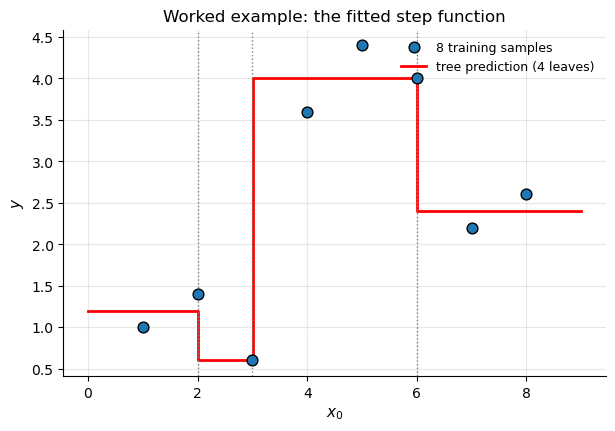

In [21]:
print("predict([[6.5], [20.0], [0.0]]) =", np.round(toy.predict(np.array([[6.5], [20.0], [0.0]])), 3))
xx = np.linspace(0, 9, 500).reshape(-1, 1)
fig, ax = plt.subplots()
ax.scatter(X_toy, y_toy, s=60, color=CLASS_COLORS[0], edgecolor="k", zorder=3, label="8 training samples")
ax.step(xx.ravel(), toy.predict(xx), where="post", color="r", lw=2, label="tree prediction (4 leaves)")
for tthr in (2, 3, 6):
    ax.axvline(tthr, color="gray", ls=":", lw=1)
ax.set(title="Worked example: the fitted step function", xlabel="$x_0$", ylabel="$y$"); ax.legend(); plt.show()

The red staircase is Eq. (0) for this tree. Its steps occur exactly at the training values $x_0 = 2, 3, 6$ (dotted lines), because thresholds are observed values tested with `<=`. A midpoint rule would put them at $2.5, 3.5, 6.5$. This is the same caveat discussed in the [classification notebook](../DecisionTree/DecisionTree_Walkthrough.ipynb).

## 7. Visual experiments

### 7.1 The fit as the tree grows

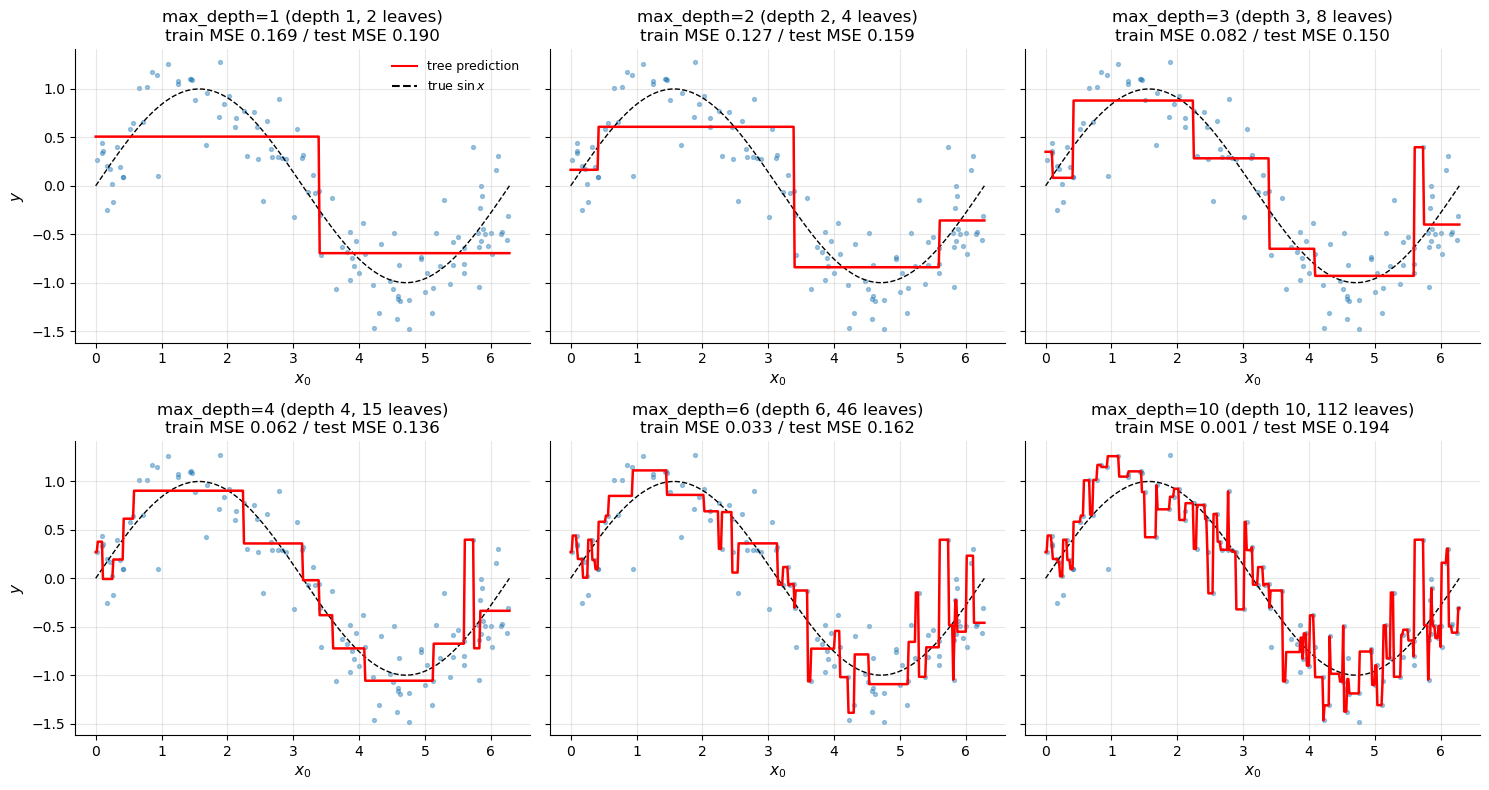

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
for ax, md in zip(axes.ravel(), [1, 2, 3, 4, 6, 10]):
    t = DecisionTreeRegressor(min_samples_split=2, max_depth=md); t.fit(X_sin, y_sin.reshape(-1, 1))
    mse_tr = np.mean((np.array(t.predict(X_sin)) - y_sin) ** 2)
    mse_te = np.mean((np.array(t.predict(X_sin_test)) - y_sin_test) ** 2)
    ax.scatter(X_sin, y_sin, s=8, alpha=0.4, color=CLASS_COLORS[0])
    ax.plot(x_grid, np.sin(x_grid), "k--", lw=1)
    ax.plot(x_grid, t.predict(x_grid), color="r", lw=1.8)
    ax.set(title=f"max_depth={md} (depth {tree_depth(t.root)}, {count_leaves(t.root)} leaves)\ntrain MSE {mse_tr:.3f} / test MSE {mse_te:.3f}",
           xlabel="$x_0$")
axes[0, 0].set_ylabel("$y$"); axes[1, 0].set_ylabel("$y$")
axes[0, 0].plot([], [], "r", label="tree prediction"); axes[0, 0].plot([], [], "k--", label="true $\\sin x$"); axes[0, 0].legend()
plt.tight_layout(); plt.show()

What to notice:
- One split (top left) gives two steps, which is the coarsest possible summary of the sine.
- At depth 3–4 the staircase follows the sine, and test MSE reaches its minimum. That minimum is still clearly above $\sigma^2 = 0.09$: the steps cannot follow a smooth curve exactly, and each leaf averages only a handful of noisy points.
- Even at depth 3, one narrow spike appears near $x_0 \approx 5.7$: a single unusually high training point has been given its own leaf. Deeper trees produce more and more such spikes.
- The deepest tree has 112 leaves for 120 training points. The staircase jumps up and down with the noise, training MSE is essentially 0, and test MSE climbs back to the level of the one-split tree. That is overfitting: leaves of one or two samples cannot average the noise away.

### 7.2 Training and test error versus depth

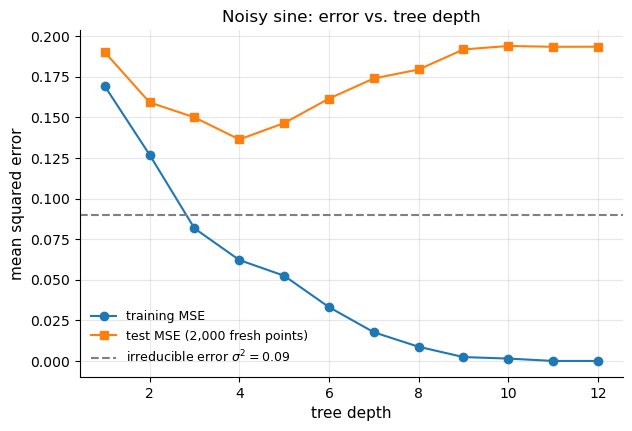

best test MSE 0.1364 at depth 4; deepest: train 0.0000, test 0.1935


In [23]:
depths, mse_tr, mse_te = [], [], []
for md in range(1, 13):
    t = DecisionTreeRegressor(min_samples_split=2, max_depth=md); t.fit(X_sin, y_sin.reshape(-1, 1))
    depths.append(tree_depth(t.root))
    mse_tr.append(np.mean((np.array(t.predict(X_sin)) - y_sin) ** 2))
    mse_te.append(np.mean((np.array(t.predict(X_sin_test)) - y_sin_test) ** 2))

fig, ax = plt.subplots()
ax.plot(depths, mse_tr, "o-", label="training MSE")
ax.plot(depths, mse_te, "s-", label="test MSE (2,000 fresh points)")
ax.axhline(SIGMA**2, color="gray", ls="--", label="irreducible error $\\sigma^2 = 0.09$")
ax.set(title="Noisy sine: error vs. tree depth", xlabel="tree depth", ylabel="mean squared error")
ax.legend(); plt.show()
print(f"best test MSE {min(mse_te):.4f} at depth {depths[int(np.argmin(mse_te))]}; deepest: train {mse_tr[-1]:.4f}, test {mse_te[-1]:.4f}")

The training error falls with every extra level, because each split can only lower training SSE (Eq. 4 is non-negative). The test error falls, bottoms out at a moderate depth (still above the irreducible $0.09$), and then rises as the tree starts fitting noise. Training error alone can never tell you when to stop.

### 7.3 Bias–variance decomposition, measured

**Math.** Imagine repeating the whole experiment many times: draw a new training set $\mathcal{D}$, fit a tree $\hat f_{\mathcal{D}}$, and predict at a fixed $x$ a fresh $y = \mu(x) + \varepsilon$. Write $\bar f(x) = E_{\mathcal{D}}[\hat f_{\mathcal{D}}(x)]$ for the average prediction over training sets. Then

$$
\begin{aligned}
E\big[(y - \hat f_{\mathcal D}(x))^2\big]
&= E\big[(\varepsilon + \mu(x) - \bar f(x) + \bar f(x) - \hat f_{\mathcal D}(x))^2\big] \\
&= \underbrace{\sigma^2}_{\text{noise}} + \underbrace{\big(\mu(x) - \bar f(x)\big)^2}_{\text{bias}^2} + \underbrace{E_{\mathcal D}\big[(\hat f_{\mathcal D}(x) - \bar f(x))^2\big]}_{\text{variance}} .
\end{aligned} \tag{7}
$$

All three cross terms vanish. $\varepsilon$ has mean zero and is independent of $\mathcal{D}$. $\mu(x) - \bar f(x)$ is a constant, and $E_{\mathcal D}[\bar f(x) - \hat f_{\mathcal D}(x)] = 0$ by the definition of $\bar f$. **Bias** measures how far the *average* tree is from the truth; **variance** measures how much individual trees scatter around that average.

**Illustration plus your implementation.** We fit 100 trees of each depth to 100 independent training sets (60 points each), and average the terms of Eq. (7) over a grid of $x$ values.

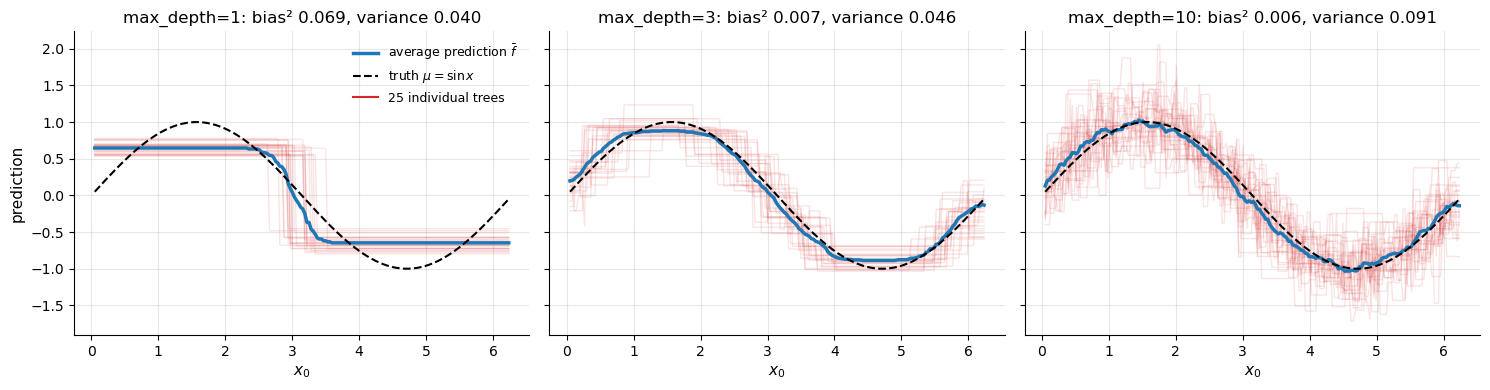

 max_depth |  bias²  variance   noise | bias²+var+noise | measured test MSE
         1 | 0.0692  0.0402  0.0900 |          0.1994 |            0.1986
         3 | 0.0072  0.0458  0.0900 |          0.1430 |            0.1432
        10 | 0.0064  0.0913  0.0900 |          0.1876 |            0.1873


In [24]:
# Monte-Carlo bias-variance decomposition (data simulation is illustration; every fit uses the repo's tree)
n_sets, n_train = 100, 60
xg = np.linspace(0.05, 2 * np.pi - 0.05, 200).reshape(-1, 1)
mu = np.sin(xg.ravel())
results = {}
for md in [1, 3, 10]:
    preds = np.empty((n_sets, len(xg)))
    for s in range(n_sets):
        Xs, ys = noisy_sine(n_train, noise=SIGMA)
        t = DecisionTreeRegressor(min_samples_split=2, max_depth=md); t.fit(Xs, ys.reshape(-1, 1))
        preds[s] = t.predict(xg)
    f_bar = preds.mean(axis=0)
    bias2, var = np.mean((f_bar - mu) ** 2), np.mean(preds.var(axis=0))
    y_new = mu[None, :] + SIGMA * rng.normal(size=preds.shape)          # fresh noisy targets for every fit
    results[md] = dict(preds=preds, f_bar=f_bar, bias2=bias2, var=var, test=np.mean((y_new - preds) ** 2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (md, r_) in zip(axes, results.items()):
    for p in r_["preds"][:25]:
        ax.plot(xg, p, color=CLASS_COLORS[1], alpha=0.12, lw=1)
    ax.plot(xg, r_["f_bar"], color=CLASS_COLORS[0], lw=2.5, label="average prediction $\\bar f$")
    ax.plot(xg, mu, "k--", lw=1.5, label="truth $\\mu = \\sin x$")
    ax.set(title=f"max_depth={md}: bias² {r_['bias2']:.3f}, variance {r_['var']:.3f}", xlabel="$x_0$")
axes[0].set_ylabel("prediction"); axes[0].plot([], [], color=CLASS_COLORS[1], label="25 individual trees"); axes[0].legend()
plt.tight_layout(); plt.show()

print(" max_depth |  bias²  variance   noise | bias²+var+noise | measured test MSE")
for md, r_ in results.items():
    total = r_["bias2"] + r_["var"] + SIGMA**2
    print(f"{md:>10} | {r_['bias2']:.4f}  {r_['var']:.4f}  {SIGMA**2:.4f} | {total:>15.4f} | {r_['test']:>17.4f}")
    assert abs(total - r_["test"]) / r_["test"] < 0.05

Eq. (7) checks out: in every row, the sum bias² + variance + noise matches the separately measured test MSE to within Monte-Carlo error (the `assert` allows 5%).

The three panels show the tradeoff directly:
- **Shallow tree (`max_depth=1`, two leaves).** The individual trees (thin red lines) all have the same two-step shape. Their average is a crude step far from the sine, so **bias dominates**. The variance is not negligible either, because the position of the single threshold jitters from one training set to the next. That jitter is visible as the smeared step near $x_0 \approx 3$.
- **Medium tree (`max_depth=3`).** The average follows the sine closely, so bias falls by an order of magnitude, while variance barely increases. This gives the lowest total error.
- **Deep tree (`max_depth=10`).** The *average* tree is as close to the sine as the medium tree's (bias stays tiny), because deep trees are flexible. But each individual tree is a jagged copy of its own noisy training set, so variance doubles and **variance dominates**.

This is the key insight behind the ensemble methods in this repo. A deep tree's error is mostly variance, and averaging many deep trees trained on different data shrinks variance while leaving the low bias intact. [Random Forests](../RandomForest/RandomForest_Walkthrough.ipynb) do exactly that. A shallow tree's error is mostly bias, and [boosting](../GradientBoostRegression/GradientBoostRegression_Walkthrough.ipynb) reduces bias by adding many shallow trees, each correcting the last.

### 7.4 Two dimensions, and no extrapolation

A two-feature target, $\mu(x_0, x_1) = \sin(x_0)\cos(x_1)$ on $[0,3]^2$, shows the axis-aligned box structure. The 1-D panel on the right shows what happens outside the training range.

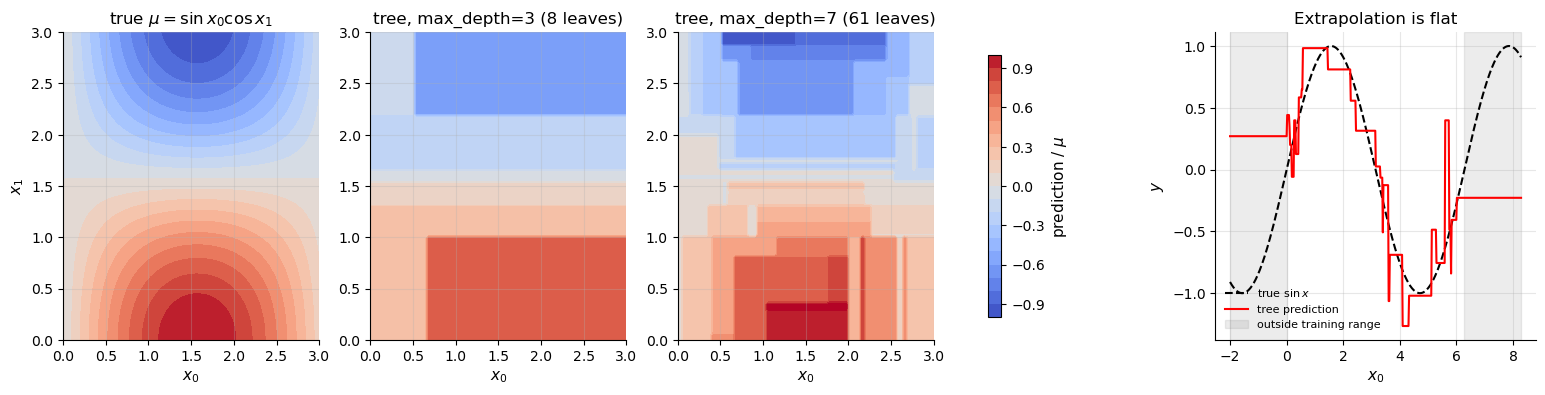

In [25]:
X2 = rng.uniform(0, 3, size=(300, 2))
y2 = np.sin(X2[:, 0]) * np.cos(X2[:, 1]) + 0.1 * rng.normal(size=300)
g = np.linspace(0, 3, 80); G0, G1 = np.meshgrid(g, g); grid2 = np.c_[G0.ravel(), G1.ravel()]

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
im = axes[0].contourf(G0, G1, np.sin(G0) * np.cos(G1), levels=20, cmap="coolwarm", vmin=-1, vmax=1)
axes[0].set(title="true $\\mu = \\sin x_0 \\cos x_1$", xlabel="$x_0$", ylabel="$x_1$")
for ax, md in zip(axes[1:3], [3, 7]):
    t = DecisionTreeRegressor(min_samples_split=5, max_depth=md); t.fit(X2, y2.reshape(-1, 1))
    ax.contourf(G0, G1, np.array(t.predict(grid2)).reshape(G0.shape), levels=20, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set(title=f"tree, max_depth={md} ({count_leaves(t.root)} leaves)", xlabel="$x_0$")
fig.colorbar(im, ax=axes[:3], shrink=0.85, label="prediction / $\\mu$")

t_ex = DecisionTreeRegressor(min_samples_split=2, max_depth=5); t_ex.fit(X_sin, y_sin.reshape(-1, 1))
x_wide = np.linspace(-2, 2 * np.pi + 2, 500).reshape(-1, 1)
axes[3].plot(x_wide, np.sin(x_wide), "k--", label="true $\\sin x$")
axes[3].plot(x_wide, t_ex.predict(x_wide), "r", label="tree prediction")
axes[3].axvspan(-2, 0, color="gray", alpha=0.15); axes[3].axvspan(2 * np.pi, 2 * np.pi + 2, color="gray", alpha=0.15, label="outside training range")
axes[3].set(title="Extrapolation is flat", xlabel="$x_0$", ylabel="$y$"); axes[3].legend(fontsize=8)
plt.show()

In 2-D, the tree approximates the smooth surface by rectangles of constant colour; deeper trees use smaller rectangles. In the right panel, the true function keeps oscillating outside $[0, 2\pi]$ (grey bands), but the tree simply repeats the value of its outermost leaf on each side, because no threshold lies beyond the last training point. Trees **interpolate** reasonably but cannot **extrapolate** trends.

## 8. Hyperparameters

`DecisionTreeRegressor(min_samples_split=2, max_depth=2)` has the same two pre-pruning controls as the classifier: `max_depth` (`None` for unlimited) and `min_samples_split`. In regression, `min_samples_split` has an extra interpretation. A leaf's value is an average of its samples, and the standard error of an average of $k$ noisy values is $\sigma/\sqrt{k}$. Forbidding small nodes therefore guarantees that leaves average enough samples to suppress noise.

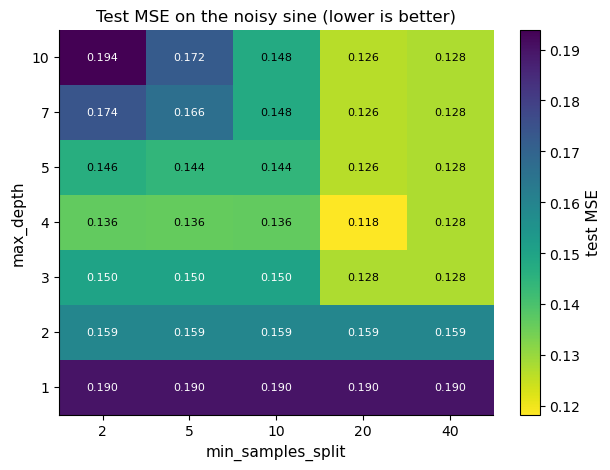

best: max_depth=4, min_samples_split=20, test MSE 0.1183 (irreducible error 0.09)


In [26]:
md_grid, mss_grid = [1, 2, 3, 4, 5, 7, 10], [2, 5, 10, 20, 40]
mse_grid = np.zeros((len(md_grid), len(mss_grid)))
for a, md in enumerate(md_grid):
    for b_, mss in enumerate(mss_grid):
        t = DecisionTreeRegressor(min_samples_split=mss, max_depth=md); t.fit(X_sin, y_sin.reshape(-1, 1))
        mse_grid[a, b_] = np.mean((np.array(t.predict(X_sin_test)) - y_sin_test) ** 2)

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(mse_grid, cmap="viridis_r", aspect="auto", origin="lower")
ax.set_xticks(range(len(mss_grid)), mss_grid); ax.set_yticks(range(len(md_grid)), md_grid)
for a in range(len(md_grid)):
    for b_ in range(len(mss_grid)):
        ax.text(b_, a, f"{mse_grid[a, b_]:.3f}", ha="center", va="center", fontsize=8,
                color="w" if mse_grid[a, b_] > np.median(mse_grid) else "k")
ax.set(title="Test MSE on the noisy sine (lower is better)", xlabel="min_samples_split", ylabel="max_depth")
ax.grid(False); fig.colorbar(im, label="test MSE"); plt.show()
a_best, b_best = np.unravel_index(np.argmin(mse_grid), mse_grid.shape)
print(f"best: max_depth={md_grid[a_best]}, min_samples_split={mss_grid[b_best]}, test MSE {mse_grid[a_best, b_best]:.4f} "
      f"(irreducible error {SIGMA**2:.2f})")

The pattern mirrors the classification heat-map. The shallowest rows have high error (bias) whatever the node size. Deep trees with tiny `min_samples_split` overfit (variance). Raising `min_samples_split` rescues the deep trees, because it forces each leaf to average more samples: in the top row, test MSE falls substantially as the minimum node size grows from 2 to 20. The best cell combines a moderate depth with a moderate node size, and it is the closest any single tree gets to the irreducible error.

## 9. Complexity and limitations

**Cost.** Identical to the classification tree: $O(m\,|S|^2)$ per node because of the list-comprehension `split`, $O(D\,m\,n^2)$ for a depth-$D$ tree, and $O(D)$ per prediction. (Variance is as cheap to compute as Gini.) Production implementations sort each feature once and sweep the thresholds while maintaining running sums $\sum y$ and $\sum y^2$ on each side. Then every candidate's $\Delta$ costs $O(1)$ via Eq. (5), and a node costs $O(m\,|S|\log|S|)$.

| Limitation of `RegressionTree.py` | Consequence | What e.g. scikit-learn does |
|---|---|---|
| $O(m n^2)$ per level split search | slow for thousands of rows (`Main.py`'s 1,503-row airfoil data is already sluggish) | sort + running sums: $O(1)$ per candidate |
| Thresholds at observed values | steps sit on training points (§6) | midpoints |
| Only squared error / mean leaves | sensitive to outliers | also `absolute_error` (median leaves), `poisson`, `friedman_mse` |
| Only pre-pruning | depth must be tuned by hand | `min_samples_leaf`, `ccp_alpha` post-pruning |
| Piecewise-constant, no extrapolation | jagged fits; flat beyond the data (§7.4) | same; use ensembles, or linear-leaf models |

Bugs found during this walkthrough and **fixed in the code**:

| Original behaviour | Fix |
|---|---|
| `curr_depth<=max_depth`: trees one level deeper than requested | strict `<`; `max_depth=None` allowed (§4.4) |
| Empty `best_split` → `KeyError` on nodes of identical rows | such a node becomes a leaf (§4.4) |
| `fit` required `Y` of shape `(n, 1)` | 1-D targets accepted; inputs validated (§5) |
| Constant-target nodes searched for splits | skipped with `np.ptp(Y) > 0` (§4.4) |
| `Main.py` printed an RMSE labelled "Mean squared error"; swapped docstrings; unused `best_split = {}`; `tree.value != None` | label, docstrings and identity tests corrected (§5) |

## 10. Summary

- Under squared error, the best predictor is the conditional mean $E[y\mid x]$. A regression tree estimates it with a **step function** (Eq. 0) whose leaves predict **sample means**, the SSE-minimising constants (Eq. 1).
- A node's variance is its mean squared error when it predicts its own mean (Eq. 2). Splits are scored by **variance reduction** (Eq. 3), which equals the drop in training SSE divided by $|S|$ (Eq. 4) and has the closed form $\Delta = w_L w_R(\bar y_L - \bar y_R)^2 \ge 0$ (Eq. 5). The criterion rewards **balanced** splits with **well-separated** child means.
- `DecisionTreeRegressor` searches every feature and observed value (Eq. 6), recurses with the same stopping rules as the classifier, and predicts by routing. The worked example reproduced every gain and leaf value by hand.
- Test error decomposes into **noise + bias² + variance** (Eq. 7), confirmed by simulation. Shallow trees are biased, deep trees have high variance, and ensembles attack one or the other.
- Fixed in `RegressionTree.py` and `Main.py` during this walkthrough: the off-by-one in `max_depth`, the `KeyError` on identical rows, 1-D targets, the RMSE label, the swapped docstrings, and an unused variable. The remaining design caveat is that thresholds sit on training points.

**Next:** averaging many deep trees to cut variance: [Random Forest](../RandomForest/RandomForest_Walkthrough.ipynb).